In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shuvoalok/ck-dataset")

print("Path to dataset files:", path)

100%|██████████| 1.80M/1.80M [00:00<00:00, 108MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/shuvoalok/ck-dataset/versions/1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Found 981 files belonging to 7 classes.
Using 785 files for training.
Found 981 files belonging to 7 classes.
Using 196 files for validation.
Detected classes: ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - accuracy: 0.3325 - loss: 1.7726
Epoch 2/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.5911 - loss: 1.3262
Epoch 3/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.7197 - loss: 0.7846
Epoch 4/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 0.8586 - loss: 0.4523
Epoch 5/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.8968 - loss: 0.3125
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8980 - loss: 0.3617


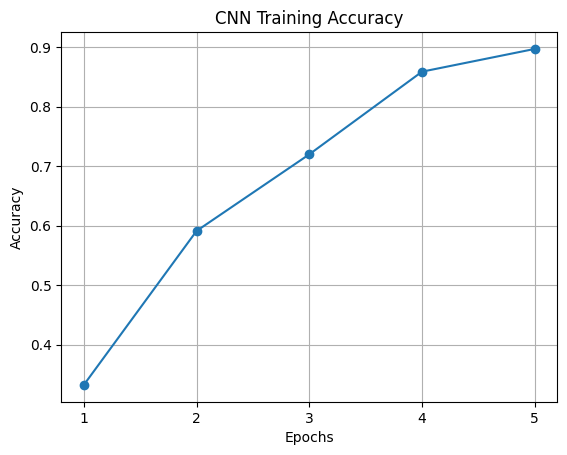

In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models

# Load training dataset (80%)
train = tf.keras.utils.image_dataset_from_directory(
    path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(48, 48),
    color_mode="grayscale",
    batch_size=32
)

# Load testing/validation dataset (20%)
test = tf.keras.utils.image_dataset_from_directory(
    path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(48, 48),
    color_mode="grayscale",
    batch_size=32
)

# Identify number of classes automatically
num_classes = len(train.class_names)
print("Detected classes:", train.class_names)

# Build CNN model
model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(48, 48, 1)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(train, epochs=5)

# Evaluate model
model.evaluate(test)

# Plot training accuracy
plt.plot(history.history['accuracy'], marker='o')

plt.title('CNN Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.xticks(range(5), range(1, 6))
plt.grid(True)

plt.show()

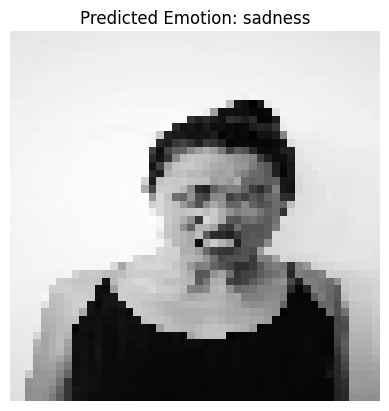

Predicted Emotion: sadness


In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------
# Detect emotion from one image
# ------------------------------------------------




# Load one facial image
img_path = "/content/emotion.jfif"  # Replace with your image path

img = tf.keras.utils.load_img(
    img_path,
    target_size=(48, 48),
    color_mode="grayscale"
)

# Convert image into array
img_array = tf.keras.utils.img_to_array(img)

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Predict emotion
prediction = model.predict(img_array, verbose=0)

# Get predicted class
class_index = np.argmax(prediction[0])
emotion = train.class_names[class_index]

# Display image and predicted emotion
plt.imshow(img, cmap='gray')
plt.title("Predicted Emotion: " + emotion)
plt.axis('off')
plt.show()

print("Predicted Emotion:", emotion)